# 19 - Netflix Subscriptions Forecasting: how far can 42 quarters be trusted?
**Topic:** Time Series  |  **Reference:** "Netflix Subscriptions Forecasting using Python" (amanxai.com, Aug 2023)

**Question.** How many paying subscribers will Netflix have in the next few quarters?

**Reference method:** read the ACF/PACF plots of the differenced series, pick ARIMA(1,1,1), fit on all 42 quarters and forecast the next 10 quarters. No test of the forecast.
**What I do:** compare ARIMA with simpler baselines (last value, last value plus average growth, linear trend) and with exponential smoothing, using **rolling-origin back-testing** (fit on the past, forecast the next 1-4 quarters, move forward, repeat); look at errors **before and after the 2022 slowdown**; check whether the **prediction intervals** contain the truth as often as they claim; then forecast 8 quarters with the best method and say what the forecast can and cannot tell.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
df = pd.read_csv("../_data/netflix_subs/Netflix-Subscriptions.csv"); df["date"] = pd.to_datetime(df["Time Period"], format="%d/%m/%Y")
s = pd.Series(df.Subscribers.to_numpy() / 1e6, index=pd.PeriodIndex(df.date, freq="Q"), name="subscribers_m")
print(len(s), "quarterly observations,", s.index[0], "to", s.index[-1], "| first %.1f M, last %.1f M" % (s.iloc[0], s.iloc[-1])); s.tail(6).round(2)

42 quarterly observations, 2013Q2 to 2023Q3 | first 34.2 M, last 238.4 M


date
2022Q2    221.64
2022Q3    220.67
2022Q4    223.09
2023Q1    230.75
2023Q2    232.50
2023Q3    238.39
Freq: Q-DEC, Name: subscribers_m, dtype: float64

**Note on dates.** The file's dates are the first day of a month (e.g. 01/07/2023) and appear to be reporting dates; I use them as given and call each row a "quarter". Values are in millions of paying subscribers.

## 2. Look at the data first

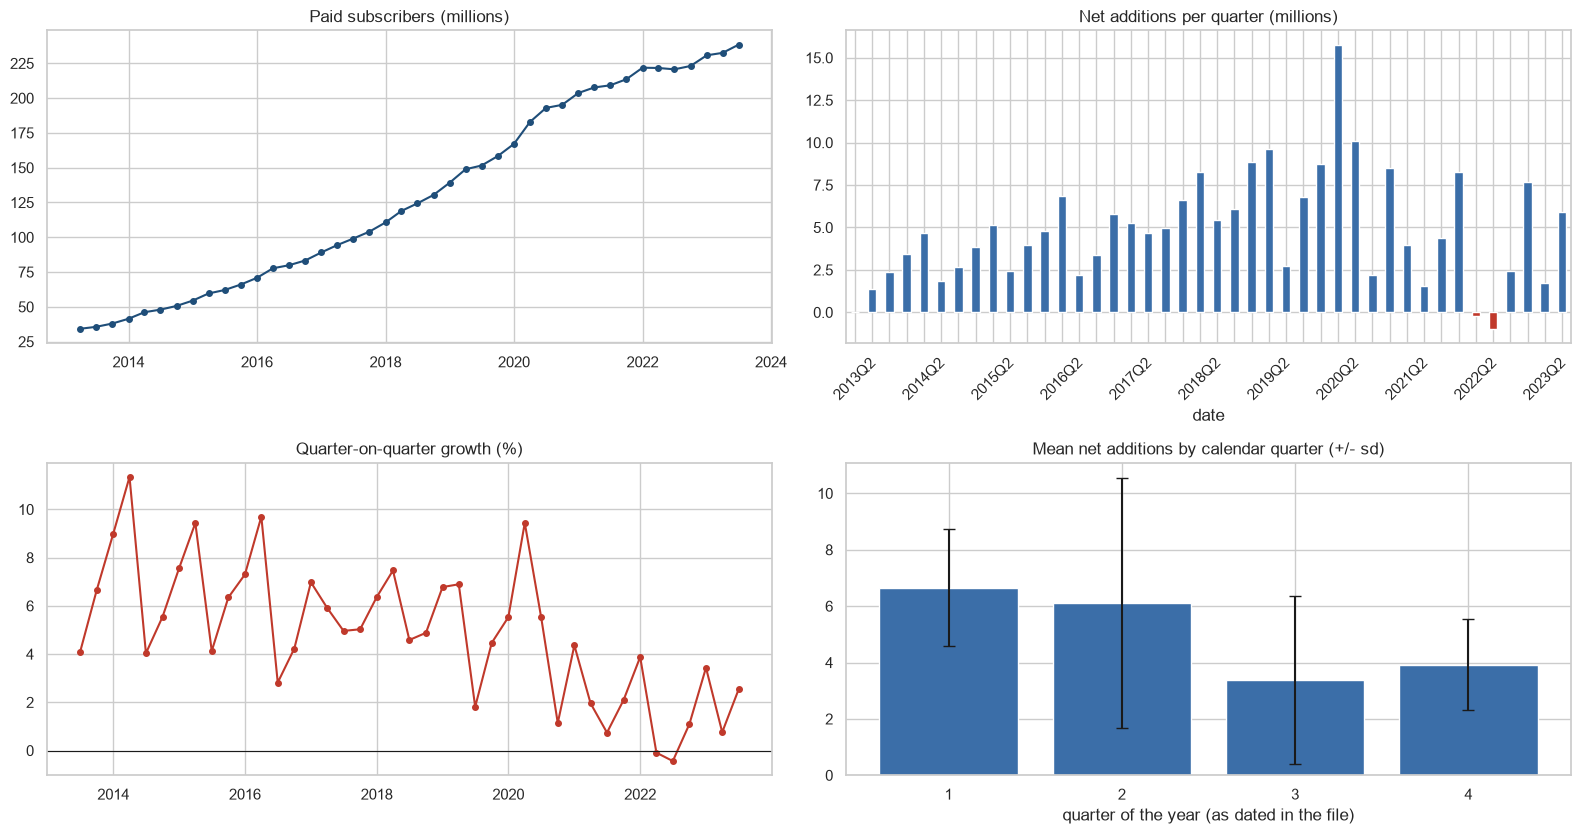

largest net additions: {Period('2020Q2', 'Q-DEC'): 15.8, Period('2020Q3', 'Q-DEC'): 10.1, Period('2019Q2', 'Q-DEC'): 9.6}
smallest (or negative): {Period('2022Q3', 'Q-DEC'): -1.0, Period('2022Q2', 'Q-DEC'): -0.2, Period('2013Q3', 'Q-DEC'): 1.4}
ADF test on levels             statistic -2.73, p = 0.225
ADF test on first differences  statistic -4.52, p = 0.000
ADF test on second differences statistic -6.85, p = 0.000


In [2]:
net = s.diff(); gr = s.pct_change() * 100
fig, ax = plt.subplots(2, 2, figsize=(16, 8.5))
ax[0, 0].plot(s.index.to_timestamp(), s.values, "o-", color="#1f4e79", ms=4); ax[0, 0].set_title("Paid subscribers (millions)")
net.plot.bar(ax=ax[0, 1], color=np.where(net.fillna(0) < 0, "#c0392b", "#3b6ea8")); ax[0, 1].set_title("Net additions per quarter (millions)"); ax[0, 1].set_xticklabels([str(i) if k % 4 == 0 else "" for k, i in enumerate(net.index)], rotation=45)
ax[1, 0].plot(gr.index.to_timestamp(), gr.values, "o-", color="#c0392b", ms=4); ax[1, 0].set_title("Quarter-on-quarter growth (%)"); ax[1, 0].axhline(0, color="k", lw=.8)
q = net.dropna().groupby(net.dropna().index.quarter).agg(["mean", "std", "count"]); ax[1, 1].bar(q.index.astype(str), q["mean"], yerr=q["std"], color="#3b6ea8", capsize=4); ax[1, 1].set_title("Mean net additions by calendar quarter (+/- sd)"); ax[1, 1].set_xlabel("quarter of the year (as dated in the file)")
plt.tight_layout(); plt.show()
print("largest net additions:", net.nlargest(3).round(1).to_dict()); print("smallest (or negative):", net.nsmallest(3).round(1).to_dict())
for lab, x in [("levels", s), ("first differences", s.diff().dropna()), ("second differences", s.diff().diff().dropna())]:
    st = adfuller(x, regression="ct" if lab == "levels" else "c"); print("ADF test on %-18s statistic %.2f, p = %.3f" % (lab, st[0], st[1]))

**Reading it.**
* 42 quarters, from 34.2 million paid subscribers to 238.4 million. The level climbs almost without a break, but the **net additions** are not constant: the largest are 15.8 M (2020Q2), 10.1 M (2020Q3) and 9.6 M (2019Q2); in **2022Q2 (-0.2 M) and 2022Q3 (-1.0 M) the count fell**, the only negative quarters. Growth in percent per quarter shrinks steadily over the decade.
* The Dickey-Fuller test cannot reject a unit root in the levels (p = 0.23) but strongly rejects it for the first differences (p < 0.001), so one difference (d = 1) is a reasonable choice, as in the reference.
* The reference states that the growth "is not seasonal". The by-quarter bar chart does show different average net additions by calendar quarter, but the standard deviations are large and each bar rests on about 10 quarters, so it is weak evidence either way.

## 3. The reference's identification step
ACF and PACF of the first-differenced series, as in the reference. With 41 differences these plots have wide confidence bands (about +/-0.31): small spikes are not distinguishable from zero.

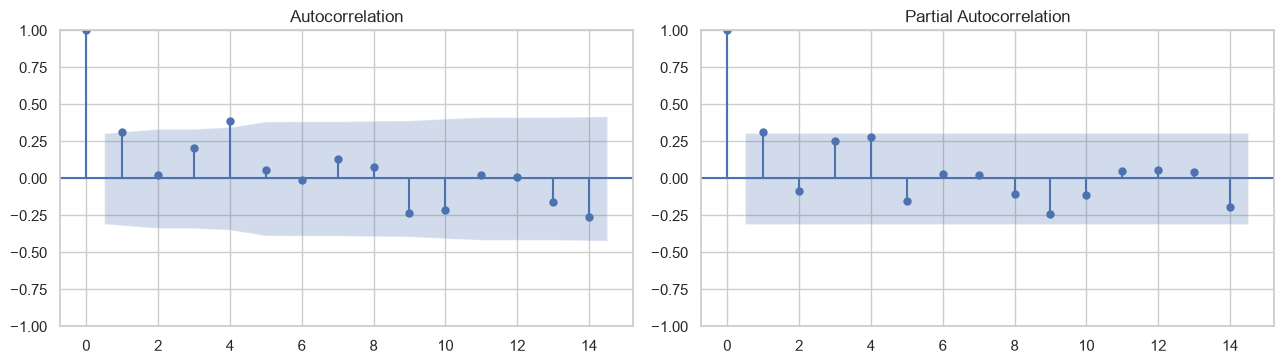

In [3]:
d1 = s.diff().dropna(); fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); plot_acf(d1, ax=ax[0], lags=14); plot_pacf(d1, ax=ax[1], lags=14, method="ywm"); plt.tight_layout(); plt.show()

**Reading it.** On the differenced series the lag-1 autocorrelation (about 0.31) just touches the 95% band (about +/-0.31), and the lag-4 spike (about 0.39 in the ACF, 0.27 in the PACF) is the only one clearly outside it: a **yearly pattern in the net additions** that an ARIMA(1,1,1) does not model. The reference's reading "ACF and PACF both cut off at lag 1, so p = q = 1" is a judgement call on a borderline spike; with 41 points these plots cannot decide between several orders, which is why I also select the order by AIC and compare against simple methods.

## 4. Models and the back-test
Each model is refit on the quarters up to the forecast origin and asked for the next 1 to 4 quarters. The first origin has 20 quarters of history; the origin then moves one quarter at a time to the end of the data (18 origins for h = 4... fewer for longer horizons).
* **Naive:** every future value = the last value.
* **Drift:** last value + (average quarterly net addition so far) x steps.
* **Recent drift:** same but using only the last 4 quarters' average net addition.
* **Linear trend** fitted on the last 12 quarters.
* **ETS damped trend** (Holt exponential smoothing with a trend that fades out).
* **ARIMA(1,1,1)**: the reference's choice, with a drift term.
* **ARIMA auto:** order (p,1,q) with p,q in 0..2 chosen by AIC at every origin.

In [4]:
H = 4; MIN = 20
def f_naive(y, h): return np.repeat(y.iloc[-1], h)
def f_drift(y, h): d = (y.iloc[-1] - y.iloc[0]) / (len(y) - 1); return y.iloc[-1] + d * np.arange(1, h + 1)
def f_rdrift(y, h): d = (y.iloc[-1] - y.iloc[-5]) / 4; return y.iloc[-1] + d * np.arange(1, h + 1)
def f_lin(y, h): t = np.arange(12); b = np.polyfit(t, y.iloc[-12:].to_numpy(), 1); return np.polyval(b, np.arange(12, 12 + h))
def f_ets(y, h): return ExponentialSmoothing(y.to_numpy(), trend="add", damped_trend=True).fit(optimized=True).forecast(h)
def f_arima111(y, h): return ARIMA(y.to_numpy(), order=(1, 1, 1), trend="t").fit().forecast(h)
def f_arima_auto(y, h):
    best = None
    for p in range(3):
        for q in range(3):
            try:
                m = ARIMA(y.to_numpy(), order=(p, 1, q), trend="t").fit()
                if best is None or m.aic < best.aic: best = m
            except Exception: pass
    return best.forecast(h)
MODELS = {"naive": f_naive, "drift (all history)": f_drift, "recent drift (last 4 quarters)": f_rdrift, "linear trend (last 12)": f_lin, "ETS damped trend": f_ets, "ARIMA(1,1,1) [reference]": f_arima111, "ARIMA auto (AIC)": f_arima_auto}
rows = []
for name, f in MODELS.items():
    for o in range(MIN, len(s) - 1):
        y = s.iloc[:o]; hh = min(H, len(s) - o); fc = f(y, hh)
        for k in range(hh): rows.append([name, o, k + 1, s.index[o + k], s.iloc[o + k], float(fc[k])])
B = pd.DataFrame(rows, columns=["model", "origin", "h", "period", "actual", "forecast"]); B["err"] = B.forecast - B.actual; B["abs"] = B.err.abs()
scale = s.diff().abs().iloc[1:MIN].mean()
tab = B.groupby(["model", "h"])["abs"].mean().unstack().round(2); tab["mean_h1-4"] = tab.mean(1); tab["MASE (h=1..4)"] = tab["mean_h1-4"] / scale
print("MAE in millions of subscribers, rolling origin (%d forecasts per model); MASE uses the average absolute quarterly change in the first %d quarters (%.2f M) as scale" % (len(B) // len(MODELS), MIN, scale)); print(tab.sort_values("mean_h1-4").round(2).to_string())

MAE in millions of subscribers, rolling origin (81 forecasts per model); MASE uses the average absolute quarterly change in the first 20 quarters (4.02 M) as scale
h                                  1      2      3      4  mean_h1-4  MASE (h=1..4)
model                                                                              
recent drift (last 4 quarters)  3.03   5.55   6.98   8.78       6.08           1.51
ETS damped trend                3.29   5.45   7.48   9.33       6.39           1.59
ARIMA auto (AIC)                3.79   5.81   6.85   9.34       6.45           1.60
ARIMA(1,1,1) [reference]        3.62   5.91   7.31   9.59       6.61           1.64
drift (all history)             3.65   5.12   7.48  10.40       6.66           1.66
linear trend (last 12)          6.16   8.45  11.45  14.54      10.15           2.52
naive                           5.91  11.60  17.39  23.18      14.52           3.61


**Reading it (81 rolling forecasts per model, errors in millions of subscribers).**
* **The simplest forecasts are as good as the sophisticated ones.** "Recent drift" (last value plus the average of the last 4 quarterly net additions) has the lowest average error (6.1 M), ETS damped 6.4, ARIMA with automatic order 6.5, the **reference's ARIMA(1,1,1) 6.6**, and drift over all history 6.7. The five are within 0.6 M of each other, far less than the error of any single forecast, and the forecasts overlap in time (they are not independent), so I would not rank them.
* The "naive" forecast (no growth) is more than twice as bad (14.5 M) and a linear trend over the last 12 quarters is poor too (10.2 M): the series trends, but the trend changes.
* **Error grows with the horizon**: about 3-4 M one quarter ahead, 5-6 M at two quarters, and **9-10 M four quarters ahead**. Every method has a MASE above 1 (1.5-1.7 for the best), i.e. worse than the typical size of one quarter's change in the early years: this series is hard to forecast beyond a quarter or two.

MAE (millions) by the period being forecast:
era                             2022 onwards (growth slows)  before 2022  ratio after/before
model                                                                                       
ETS damped trend                                       6.87         6.02            1.141196
recent drift (last 4 quarters)                         5.58         6.22            0.897106
ARIMA auto (AIC)                                       5.25         6.94            0.756484
drift (all history)                                    5.50         7.09            0.775740
ARIMA(1,1,1) [reference]                               5.26         7.15            0.735664
linear trend (last 12)                                14.66         7.71            1.901427
naive                                                  8.66        17.08            0.507026


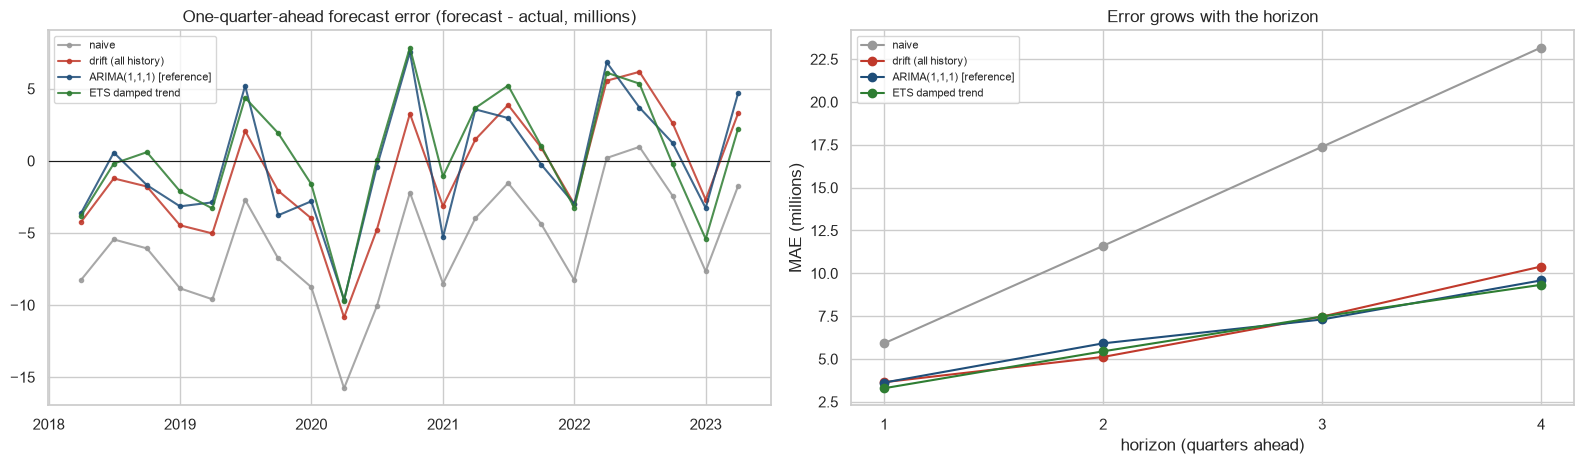

In [5]:
B["era"] = np.where(B.period >= pd.Period("2022Q1", "Q"), "2022 onwards (growth slows)", "before 2022")
era = B.groupby(["model", "era"])["abs"].mean().unstack().round(2); era["ratio after/before"] = era["2022 onwards (growth slows)"] / era["before 2022"]
print("MAE (millions) by the period being forecast:"); print(era.sort_values("before 2022").to_string())
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
pt = B[B.h == 1]
for name, c in [("naive", "#999999"), ("drift (all history)", "#c0392b"), ("ARIMA(1,1,1) [reference]", "#1f4e79"), ("ETS damped trend", "#2e7d32")]:
    d = pt[pt.model == name]; ax[0].plot(d.period.dt.to_timestamp(), d.err, "o-", ms=3, label=name, color=c, alpha=.85)
ax[0].axhline(0, color="k", lw=.8); ax[0].set_title("One-quarter-ahead forecast error (forecast - actual, millions)"); ax[0].legend(fontsize=8)
for name, c in [("naive", "#999999"), ("drift (all history)", "#c0392b"), ("ARIMA(1,1,1) [reference]", "#1f4e79"), ("ETS damped trend", "#2e7d32")]:
    d = B[B.model == name].groupby("h")["abs"].mean(); ax[1].plot(d.index, d.values, "o-", label=name, color=c)
ax[1].set_xlabel("horizon (quarters ahead)"); ax[1].set_ylabel("MAE (millions)"); ax[1].set_title("Error grows with the horizon"); ax[1].set_xticks(range(1, H + 1)); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading it.** The slowdown of 2022 hurt the **trend-extrapolating** methods most: the linear trend (fitted to the boom of 2020-21) had an error of 14.7 M on 2022 onwards against 7.7 M before; the damped ETS error rose from 6.0 to 6.9 M. Averages that adapt (recent drift 5.6 M; the ARIMAs about 5.3 M) were no worse after 2022 than before. The naive forecast looks *better* after 2022 (8.7 M vs 17.1 M) simply because the series moved less. So "which method is best" depends on the period tested; 18 origins and one structural break are too little to settle it.

## 5. Do the prediction intervals tell the truth?
For ARIMA(1,1,1) and ETS I take the forecast distribution at each origin (ARIMA: the model's 80% interval; ETS: a simulated 80% interval) and count how often the real value falls inside. A well-calibrated 80% interval contains the truth about 80% of the time.

In [6]:
cov = []
for o in range(MIN, len(s) - 1):
    y = s.iloc[:o]; hh = min(H, len(s) - o); act = s.iloc[o:o + hh].to_numpy()
    r = ARIMA(y.to_numpy(), order=(1, 1, 1), trend="t").fit(); ci = r.get_forecast(hh).conf_int(alpha=.2)
    for k in range(hh): cov.append(["ARIMA(1,1,1)", k + 1, s.index[o + k], ci[k, 0] <= act[k] <= ci[k, 1], ci[k, 1] - ci[k, 0]])
    m = ExponentialSmoothing(y.to_numpy(), trend="add", damped_trend=True).fit(); sim = m.simulate(hh, repetitions=500, error="add", random_state=0)
    lo, hi = np.percentile(sim, [10, 90], axis=1)
    for k in range(hh): cov.append(["ETS damped", k + 1, s.index[o + k], lo[k] <= act[k] <= hi[k], hi[k] - lo[k]])
CV = pd.DataFrame(cov, columns=["model", "h", "period", "inside", "width"])
print("share of actual values inside the nominal 80% interval:"); print((CV.groupby(["model", "h"]).inside.mean().unstack() * 100).round(0).to_string()); print("\nall horizons: %s | median interval width (millions): %s" % ((CV.groupby("model").inside.mean() * 100).round(0).to_dict(), CV.groupby("model").width.median().round(1).to_dict()))
print("inside rate before 2022: %s | from 2022: %s" % ((CV[CV.period < pd.Period("2022Q1", "Q")].groupby("model").inside.mean() * 100).round(0).to_dict(), (CV[CV.period >= pd.Period("2022Q1", "Q")].groupby("model").inside.mean() * 100).round(0).to_dict()))

share of actual values inside the nominal 80% interval:
h                1     2     3     4
model                               
ARIMA(1,1,1)  43.0  43.0  45.0  42.0
ETS damped    52.0  48.0  50.0  37.0

all horizons: {'ARIMA(1,1,1)': 43.0, 'ETS damped': 47.0} | median interval width (millions): {'ARIMA(1,1,1)': 11.2, 'ETS damped': 11.0}
inside rate before 2022: {'ARIMA(1,1,1)': 30.0, 'ETS damped': 43.0} | from 2022: {'ARIMA(1,1,1)': 70.0, 'ETS damped': 56.0}


**Reading it.** The nominal 80% intervals are **far too narrow**: the true value fell inside the ARIMA(1,1,1) interval only **43%** of the time (ETS: 47%), and about the same at every horizon. Before 2022 the ARIMA interval held only 30% of the outcomes; from 2022 on, 70% (the slowdown made the series calmer relative to the model's wide spread). The model assumes steady growth with constant noise; the real series has regime changes (the 2020 surge, the 2022 stall) that it does not include. So an "80%" band from this model is closer to a 45% band.

## 6. Forecast the next 8 quarters
Final fit on all 42 quarters with the reference's ARIMA(1,1,1) (with drift) and with ETS damped; I show the **80% and 95% intervals** of the ARIMA and the spread of the ETS simulation, and mark the naive value for scale.

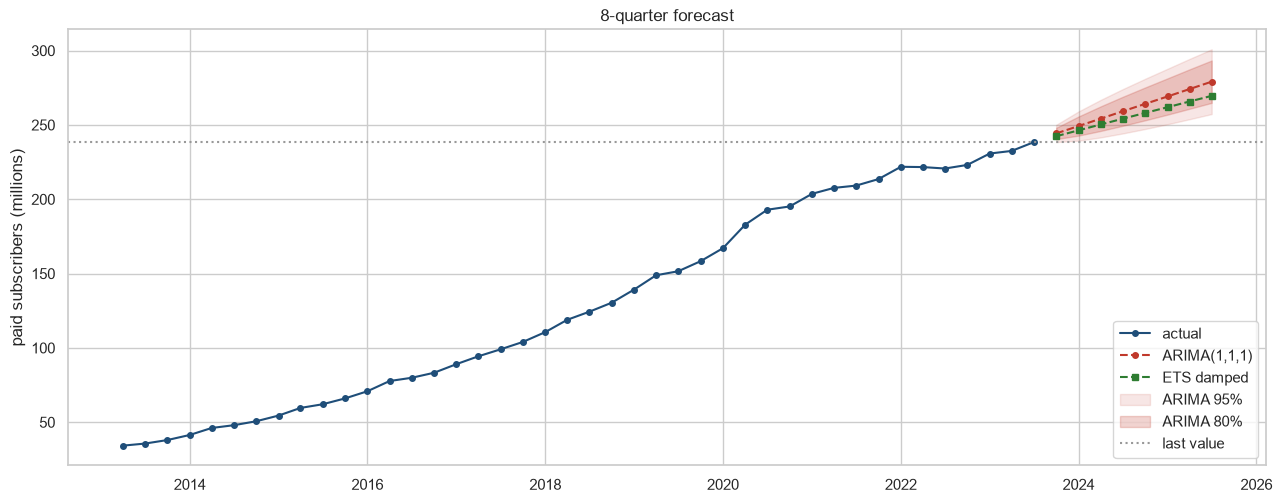

period  ARIMA  ARIMA 80% low  ARIMA 80% high  ETS damped
2023Q4  244.3          240.5           248.1       242.4
2024Q1  249.2          242.8           255.7       246.3
2024Q2  254.2          246.0           262.5       250.3
2024Q3  259.2          249.4           268.9       254.2
2024Q4  264.2          253.1           275.2       258.1
2025Q1  269.1          256.9           281.4       261.9
2025Q2  274.1          260.9           287.4       265.8
2025Q3  279.1          264.9           293.3       269.5

recent net additions (last 6 quarters, millions): [-0.2, -0.97, 2.42, 7.66, 1.75, 5.89] | ARIMA drift per quarter: 5.00 M


In [7]:
r = ARIMA(s.to_numpy(), order=(1, 1, 1), trend="t").fit(); fa = r.get_forecast(8); idx = pd.period_range(s.index[-1] + 1, periods=8, freq="Q")
ci80, ci95 = fa.conf_int(alpha=.2), fa.conf_int(alpha=.05); em = ExponentialSmoothing(s.to_numpy(), trend="add", damped_trend=True).fit(); ef = em.forecast(8)
fig, ax = plt.subplots(figsize=(13, 5.2)); x0 = s.index.to_timestamp(); x1 = idx.to_timestamp()
ax.plot(x0, s.values, "o-", color="#1f4e79", ms=4, label="actual"); ax.plot(x1, fa.predicted_mean, "o--", color="#c0392b", ms=4, label="ARIMA(1,1,1)"); ax.plot(x1, ef, "s--", color="#2e7d32", ms=4, label="ETS damped")
ax.fill_between(x1, ci95[:, 0], ci95[:, 1], color="#c0392b", alpha=.12, label="ARIMA 95%"); ax.fill_between(x1, ci80[:, 0], ci80[:, 1], color="#c0392b", alpha=.22, label="ARIMA 80%"); ax.axhline(s.iloc[-1], color="#999", ls=":", label="last value")
ax.set_ylabel("paid subscribers (millions)"); ax.set_title("8-quarter forecast"); ax.legend(); plt.tight_layout(); plt.show()
out = pd.DataFrame({"period": idx.astype(str), "ARIMA": fa.predicted_mean.round(1), "ARIMA 80% low": ci80[:, 0].round(1), "ARIMA 80% high": ci80[:, 1].round(1), "ETS damped": np.asarray(ef).round(1)}); print(out.to_string(index=False))
print("\nrecent net additions (last 6 quarters, millions):", s.diff().tail(6).round(2).tolist(), "| ARIMA drift per quarter: %.2f M" % (r.params[0] / (1 - r.params[1]) if len(r.params) > 1 else r.params[0]))

**Reading it.** ARIMA(1,1,1) with drift projects about **+5.0 M per quarter** to 279 M by 2025Q3 (80% interval 265-293 M); the damped ETS is more cautious (269.5 M). Compare with the recent past: over the last six quarters net additions averaged about 2.8 M (they were -0.2, -1.0, +2.4, +7.7, +1.8, +5.9), well below the 5.0 M drift because the drift averages a decade of faster growth. If the 2022-23 pace persists the true path would sit nearer the damped ETS or below it. Given the back-test (errors of 9-10 M four quarters out and under-coverage of the intervals), the 8-quarter horizon should be read as a scenario, not a prediction: the width of the honest range is probably 2 or more times the printed band.

## 7. Save

In [8]:
joblib.dump({"series": s, "arima": r, "ets": em}, "model/netflix_forecasters.joblib")
json.dump({"backtest_mae": tab.round(3).to_dict("index"), "era": era.round(3).to_dict("index"), "interval_coverage_pct": (CV.groupby("model").inside.mean() * 100).round(1).to_dict(), "last_obs": [str(s.index[-1]), float(s.iloc[-1])],
           "forecast": out.to_dict("records")}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['meta.json', 'netflix_forecasters.joblib']


## 8. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Model choice | ACF/PACF by eye -> ARIMA(1,1,1) | ARIMA(1,1,1), ARIMA with AIC order, ETS, drift variants, linear trend, naive |
| Evaluation | none | rolling-origin back-test, 81 forecasts per model, horizon 1-4, MASE, before/after 2022 |
| Result | a 10-quarter forecast | top five methods within 0.6 M (MAE about 6-6.7 M); naive 14.5 M; error of 9-10 M at 4 quarters |
| Uncertainty | none shown | 80% intervals contain the truth only 43-47% of the time |
| Forecast | ARIMA | 8 quarters, ARIMA +5.0 M/quarter (279 M by 2025Q3) vs ETS 269.5 M, labelled as a scenario |

**What I learned.** (1) A forecast is only as good as its back-test: the reference's model is no better than "last value plus recent growth". (2) Plot the ACF with its confidence band in mind: a borderline lag-1 spike cannot fix an order. (3) Check interval coverage: nominal 80% intervals covered 43%. (4) Series with regime changes (a pandemic surge, a slowdown) punish methods that extrapolate a fitted trend.

**Limits.** 42 points; a single series; no covariates (price changes, content releases, password-sharing policy); the back-test period contains one regime change; interval checks are based on a few dozen forecasts. **Next step:** add external regressors and a model with a changing trend (a local-linear-trend state-space model), and evaluate on a later data release.